# Forest Cover Type Classification: defense notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mara-werils/forest-cover-classification/blob/main/notebooks/Forest_Cover_Defense.ipynb)

Topic 37, Programming for AI. Team: **Amanbaev Marlen (AAI-2601)**, **Erik [surname] ([group])**,
**Rashad [surname] ([group])**.

This notebook walks through the project in the order of the pipeline. It does not contain
its own logic: each cell calls functions from `src/`, the same ones used by the console menu
(`main.py`) and the Streamlit app (`app.py`).

| Step | Module |
|---|---|
| 1. Data: download, chunked typed read, Parquet | `src/data_loader.py` |
| 2. Data quality audit | `src/audit.py` |
| 3. EDA | `src/eda.py` |
| 4. SQLite + SQL | `src/database.py`, `src/queries.py` |
| 5. Models: comparison | `src/features.py`, `src/models.py`, `src/pipeline.py` |
| 6. Evaluation, importance, errors | `src/evaluate.py` |
| 7. Prediction for user input | `src/predict.py` |

Repository: https://github.com/mara-werils/forest-cover-classification

In [1]:
# Setup: in Colab clone the repository, locally just move to the repo root.
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("forest-cover-classification").exists():
        !git clone -q https://github.com/mara-werils/forest-cover-classification.git
    %cd forest-cover-classification
    !pip install -q -r requirements.txt
else:
    root = Path.cwd()
    while not (root / "main.py").exists() and root != root.parent:
        root = root.parent
    os.chdir(root)
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /Users/marleshkaa./Desktop/Desktop - MacBook Air —  MARLEN/Master's/Programming for AI/Final Project/forest-cover-classification


In [2]:
import json
import pandas as pd
from IPython.display import Image, display
from src import config, data_loader, audit, eda, database, queries, features, models, evaluate, predict

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
config.ensure_dirs()
FIG = config.FIGURES_DIR

## 1. Data: 581,012 rows, memory-aware loading

The raw file has no header and 55 integer columns. `pd.read_csv` defaults to `int64` for all of
them. We read it in chunks of 100,000 rows with the smallest lossless dtype per column
(`int16` for elevation and distances, `uint8` for flags, angles and hillshade), then collapse
the 4 + 40 one-hot columns into two categorical columns and save Parquet.

In [3]:
df, memory = data_loader.prepare_data()
print(f"Rows: {len(df):,}, columns: {df.shape[1]}")
print(f"Default read : {memory['default_read']['memory_mb']:>7} MB  ({memory['default_read']['dtypes']})")
print(f"Chunked+typed: {memory['chunked_typed_read']['memory_mb']:>7} MB  -> -{memory['memory_reduction_pct']}%")
pd.DataFrame(memory["chunked_typed_read"]["chunks"])

Rows: 581,012, columns: 57
Default read :   243.8 MB  ({'int64': 55})
Chunked+typed:    33.8 MB  -> -86.1%


,chunk,rows,memory_mb
0,1,100000,5.82
1,2,100000,5.82
2,3,100000,5.82
3,4,100000,5.82
4,5,100000,5.82
5,6,81012,4.71


In [4]:
# CSV vs Parquet: size on disk, load time, peak RAM (approach comparison, requirement 9)
data_loader.benchmark_formats(repeats=2)

,method,file_mb,load_seconds_median,peak_ram_mb,frame_mb,rows
0,csv_default,71.69,0.897,487.8,243.8,581012
1,csv_typed,71.69,0.808,127.7,33.8,581012
2,parquet,6.91,0.083,7.3,34.9,581012
3,parquet_3_columns,6.91,0.007,1.1,2.2,581012


## 2. Data quality audit

In [5]:
report = audit.run_audit(df)
audit.print_audit(report)

Rows: 581,012  Columns: 57
Missing values: none
exact_duplicate_rows: 0
duplicate_feature_vectors: 0
feature_vectors_with_conflicting_labels: 0
wilderness: none=0, several=0
soil: none=0, several=0
Range violations: none
IQR outliers (% of rows):
  Elevation                              2.68%
  Aspect                                 0.00%
  Slope                                  2.64%
  Horizontal_Distance_To_Hydrology       2.51%
  Vertical_Distance_To_Hydrology         5.42%
  Horizontal_Distance_To_Roadways        0.12%
  Hillshade_9am                          3.00%
  Hillshade_Noon                         2.70%
  Hillshade_3pm                          1.35%
  Horizontal_Distance_To_Fire_Points     5.36%
Suspicious values: {'hillshade_3pm_zero': 1338, 'hillshade_9am_zero': 13, 'aspect_equals_360': 51, 'negative_vertical_distance': 55143}
Class shares (%):
  Spruce/Fir            36.46
  Lodgepole Pine        48.76
  Ponderosa Pine         6.15
  Cottonwood/Willow      0.47
  Aspen  

**Decisions.** No missing values, no duplicates, no rows with zero or several soil/wilderness
flags, no values outside physical ranges. IQR "outliers" (up to 5.4% for vertical distance
to water and fire points) are real terrain, not errors, so they are **kept**. Tree models are
insensitive to them, and the linear model sees them after standard scaling. 1,338 cells have
`Hillshade_3pm = 0` (full shadow), which is plausible on steep north-west slopes, so they are
also kept and flagged in the report.

## 3. Exploratory analysis

Strongest correlations: {'Hillshade_9am ~ Hillshade_3pm': -0.78, 'Aspect ~ Hillshade_3pm': 0.647, 'Horizontal_Distance_To_Hydrology ~ Vertical_Distance_To_Hydrology': 0.606, 'Hillshade_Noon ~ Hillshade_3pm': 0.594, 'Aspect ~ Hillshade_9am': -0.579}


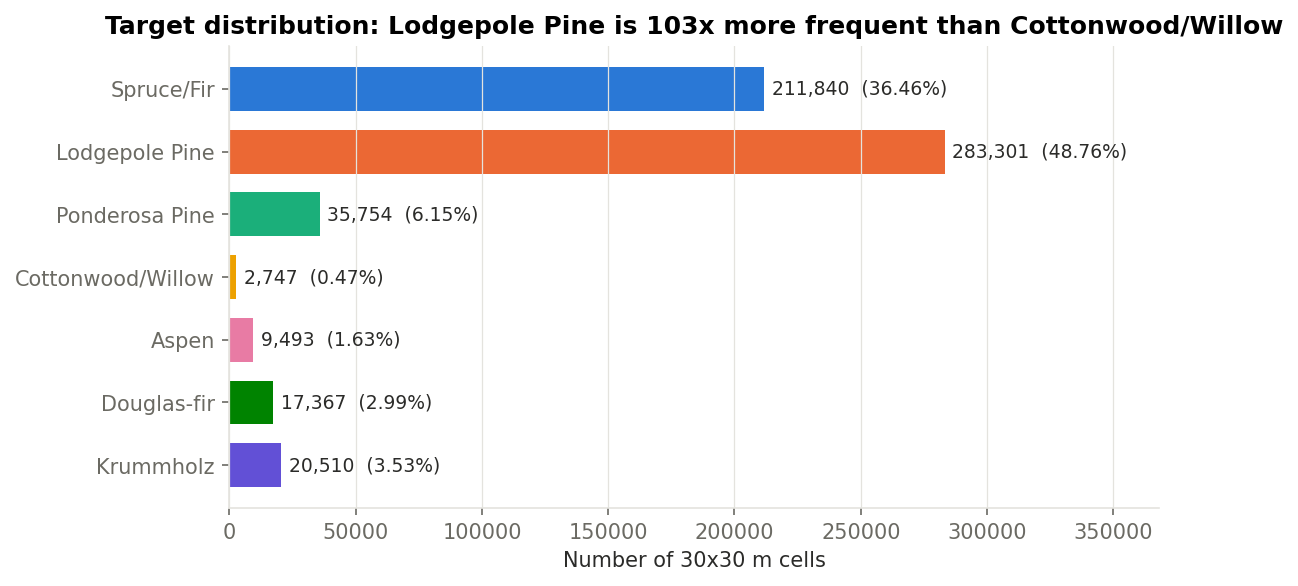

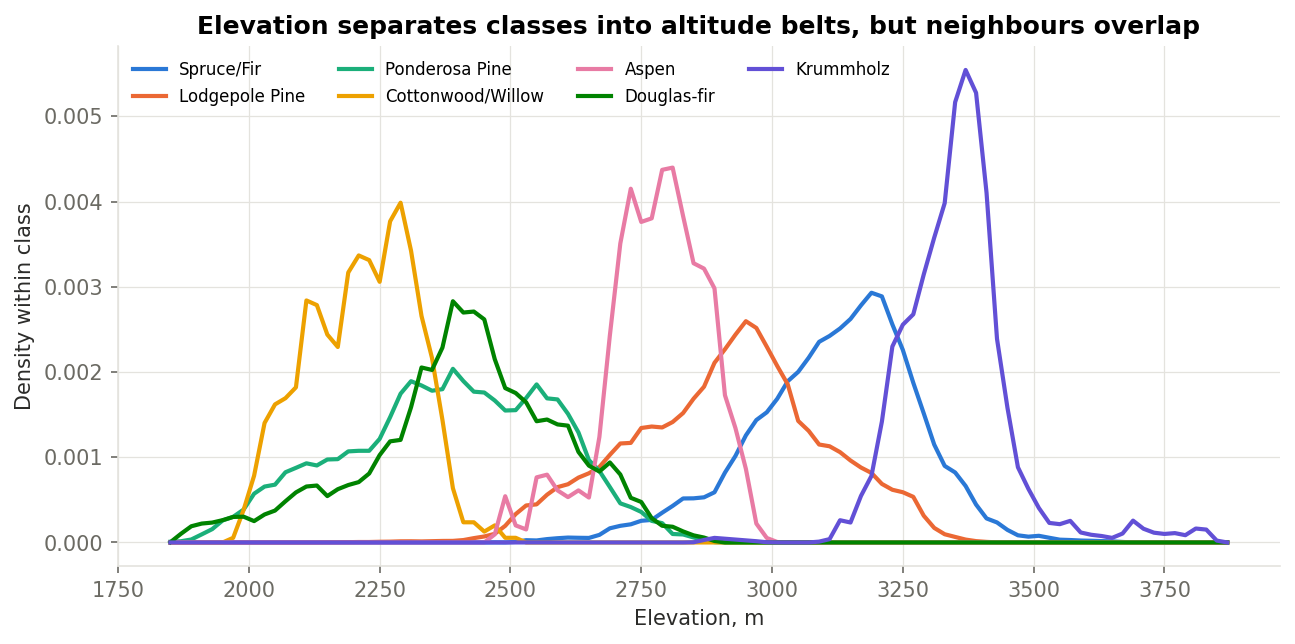

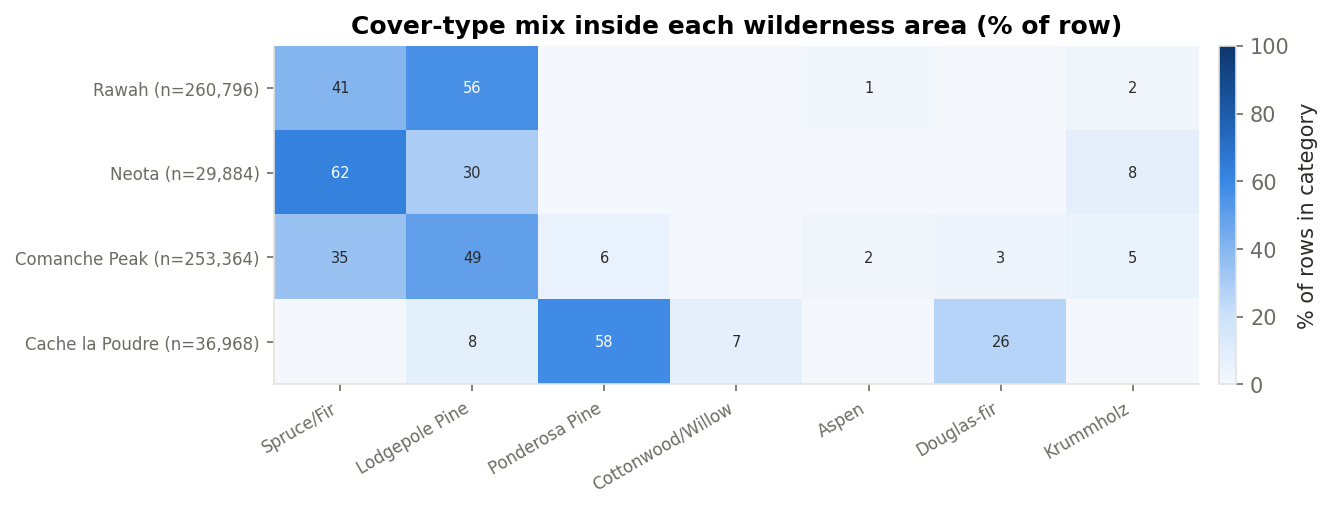

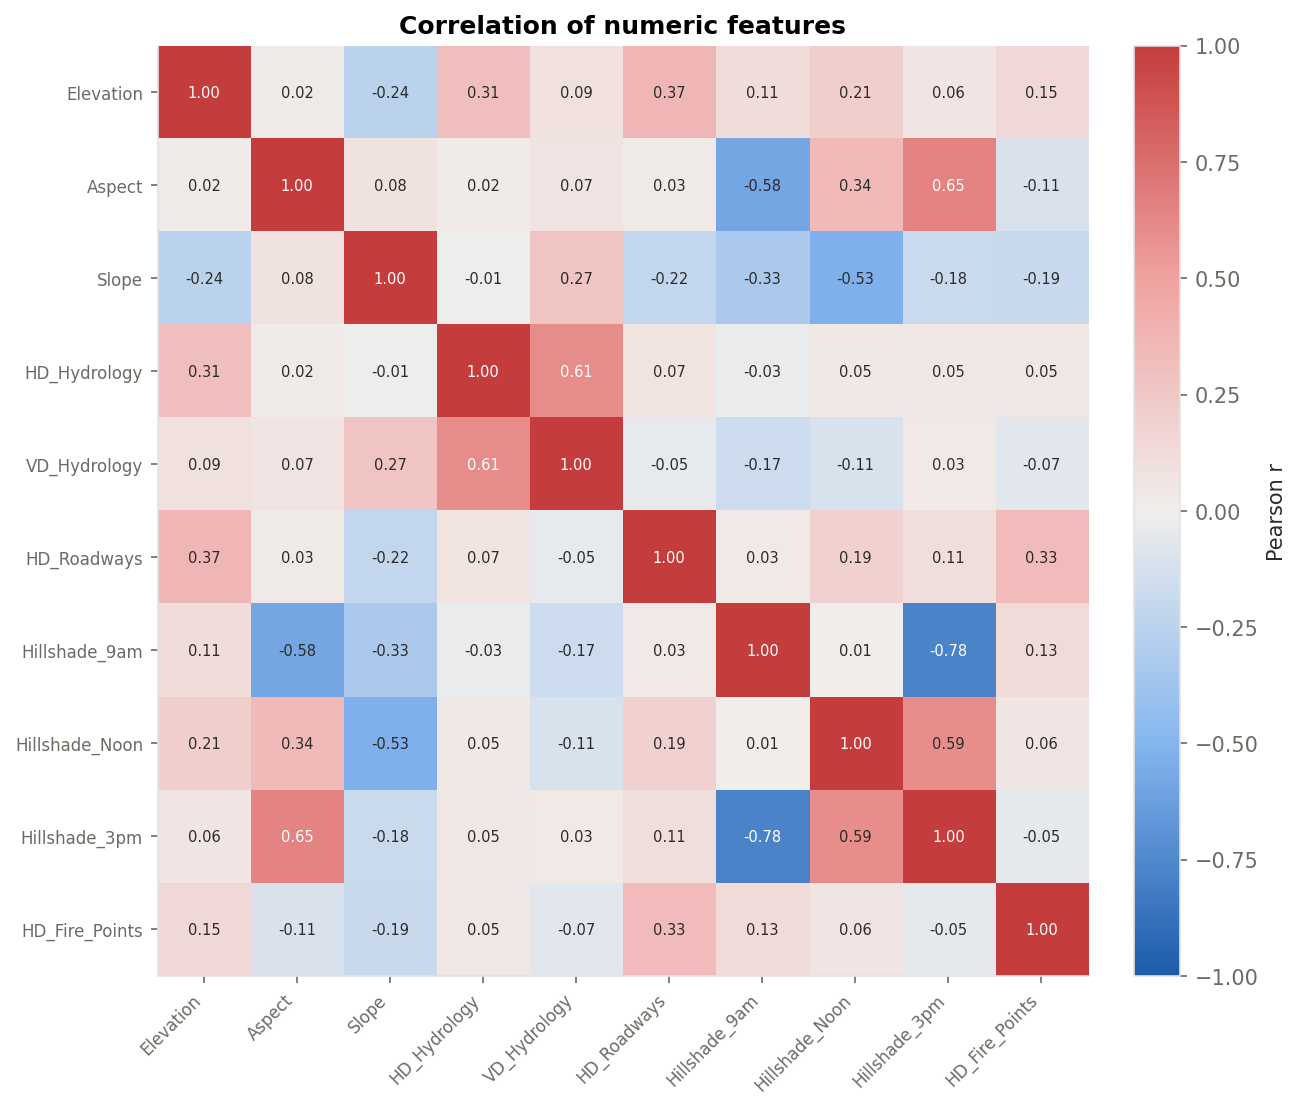

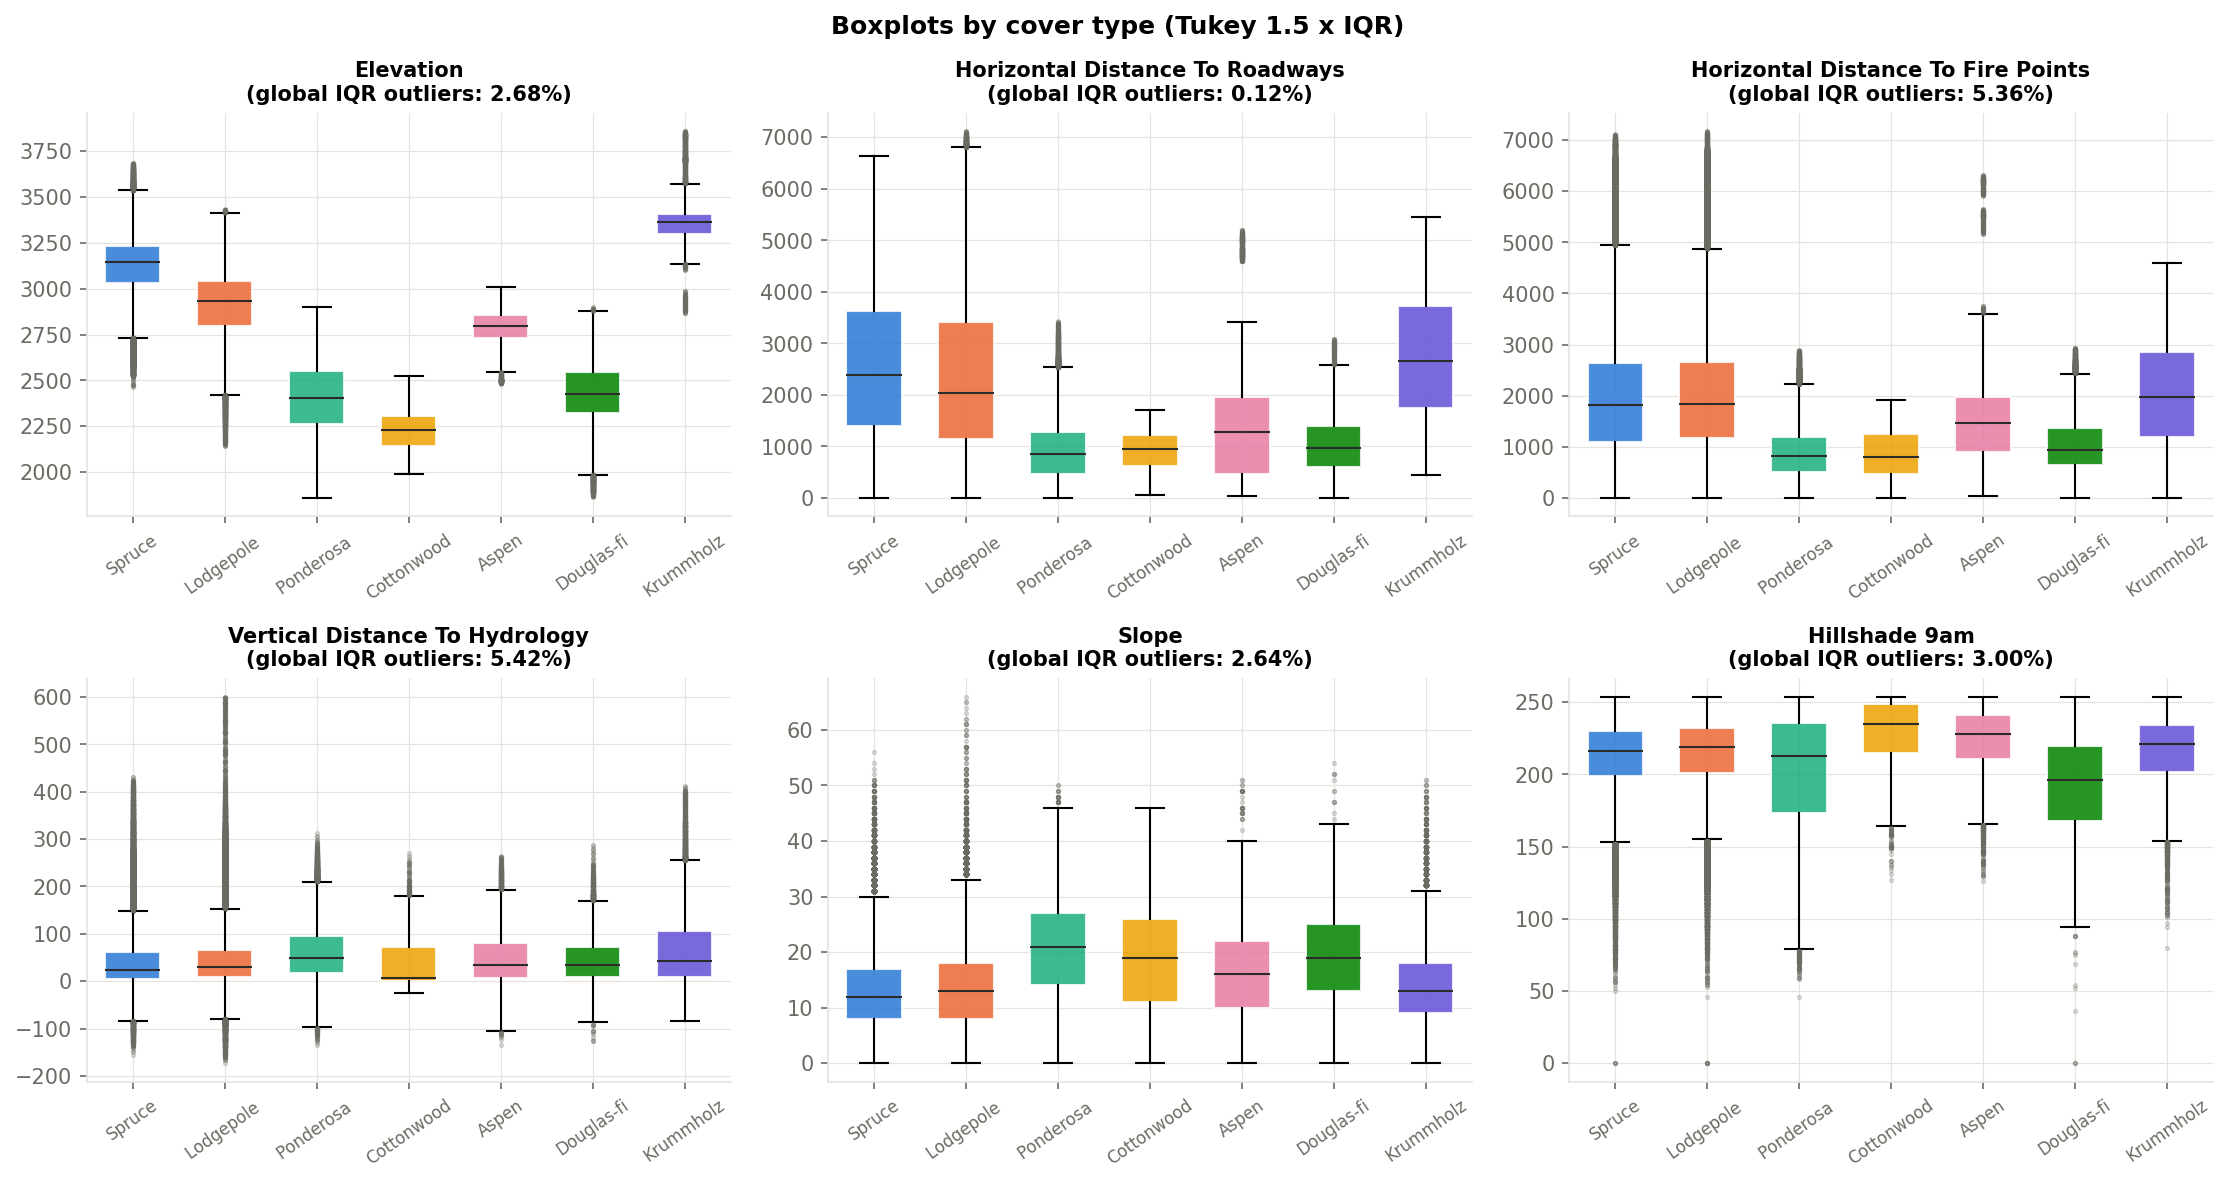

In [6]:
outputs = eda.run_eda(df, report)
print("Strongest correlations:", outputs["top_correlations"])
for name in ["01_class_distribution.png", "05_elevation_by_class.png", "06_wilderness_vs_class.png",
             "04_correlation_heatmap.png", "03_boxplots_by_class.png"]:
    display(Image(filename=str(FIG / name), width=900))

In [7]:
# Interactive Plotly chart (also saved as reports/figures/09_interactive_scatter.html)
import plotly.express as px
sample = df.sample(8000, random_state=0).assign(Cover=lambda d: d[config.TARGET].map(config.COVER_TYPES))
px.scatter(sample, x="Horizontal_Distance_To_Roadways", y="Elevation", color="Cover", opacity=0.6,
           color_discrete_map={config.COVER_TYPES[k]: v for k, v in eda.CLASS_COLORS.items()},
           template="plotly_white", title="Elevation vs distance to roads")

## 4. SQLite: normalised schema and SQL analytics

{'cover_type': 7, 'wilderness_area': 4, 'climatic_zone': 8, 'geologic_zone': 8, 'soil_type': 40, 'cell': 581012}


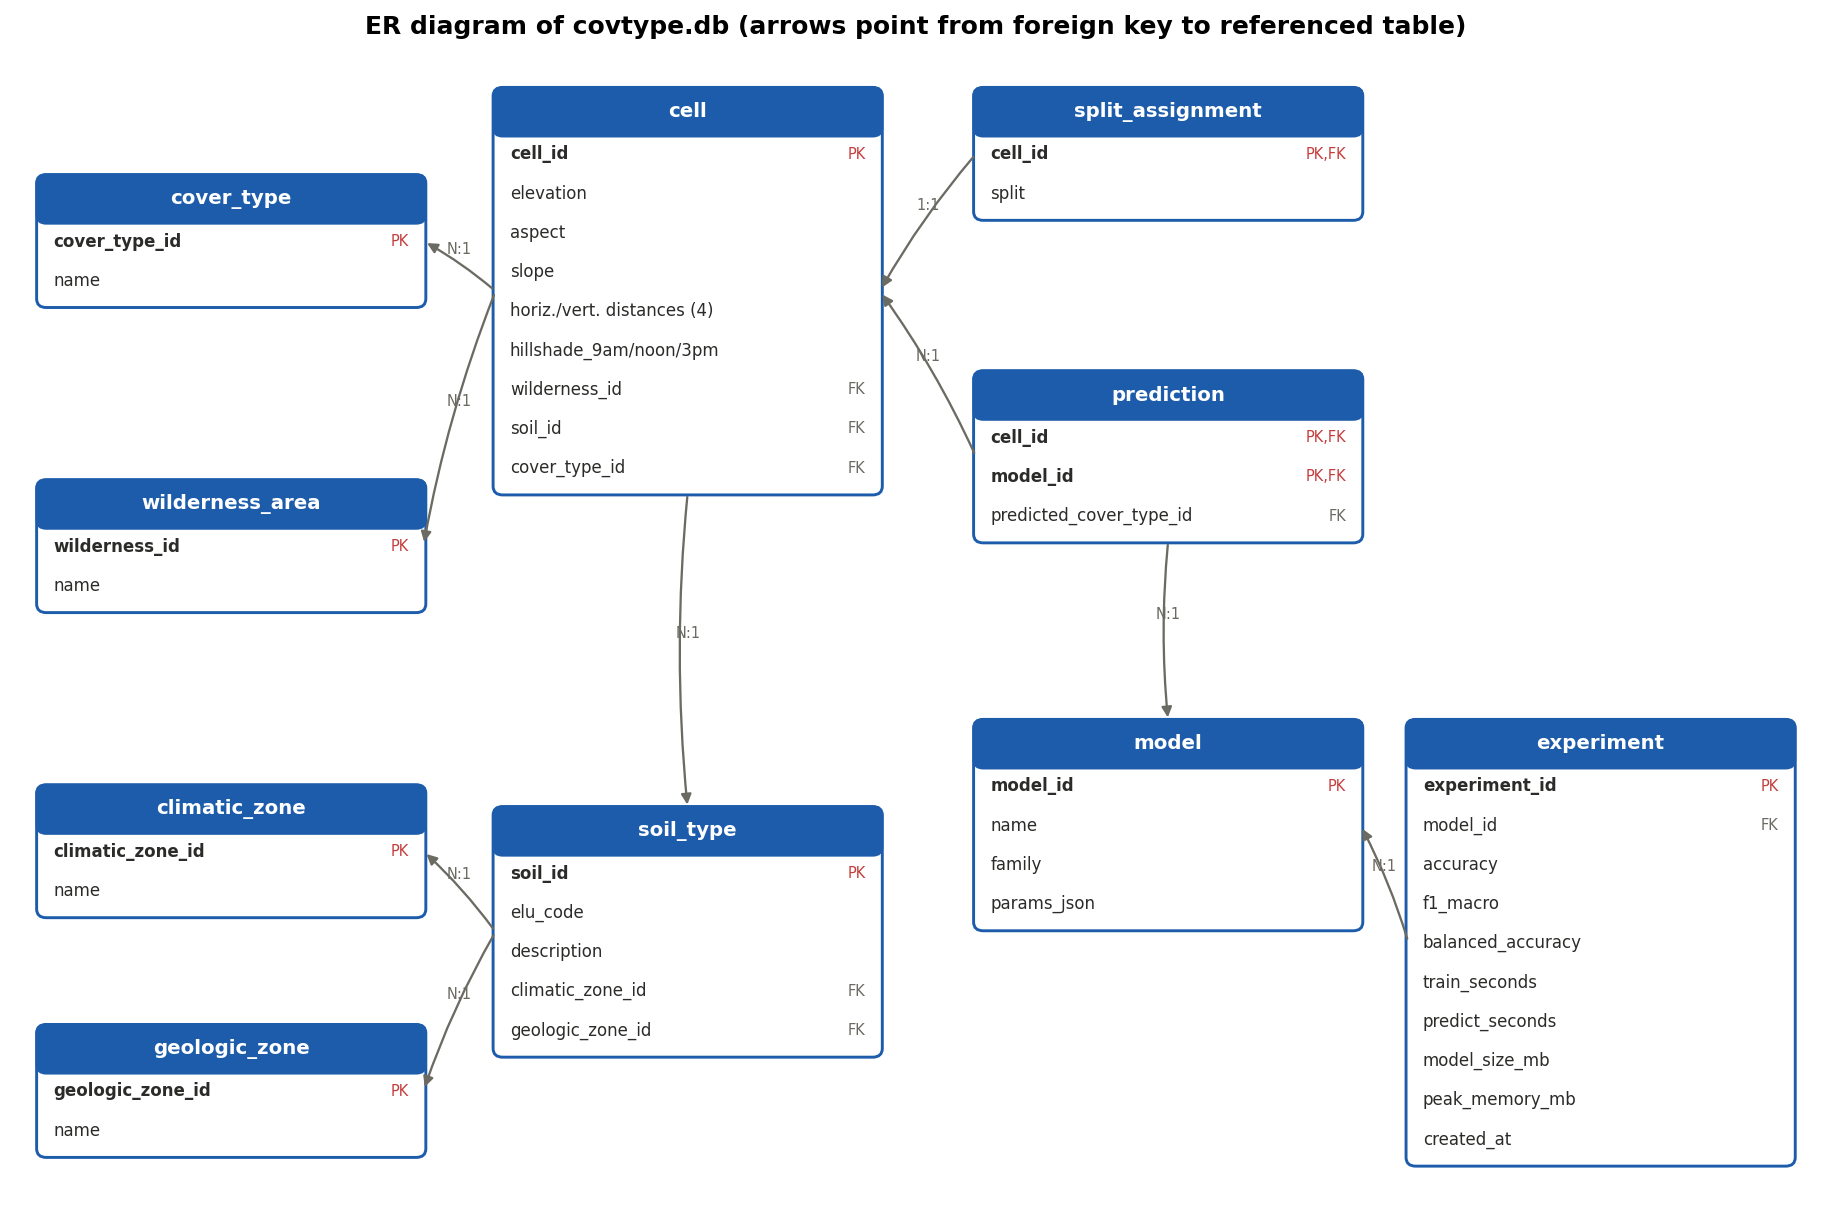

In [8]:
print(database.build_database(df))
display(Image(filename=str(FIG / "00_er_diagram.png"), width=1000))

In [9]:
summary = queries.run_all(include_predictions=False)
summary

,query,title,features,rows,seconds
0,Q01_class_distribution,Class distribution with share of total,"JOIN, GROUP BY, window SUM() OVER ()",7,0.037
1,Q02_terrain_by_class_and_area,Average terrain per cover type and wilderness ...,"2 JOINs, GROUP BY, HAVING",17,0.507
2,Q03_dominant_class_per_soil,Dominant cover type of every frequent soil type,"CTE, JOIN, GROUP BY/HAVING, ROW_NUMBER() OVER ...",31,0.273
3,Q04_elevation_bands,Cover-type mix by 200 m elevation band,"CTE, CASE, GROUP BY, window share within band",41,0.341
4,Q05_climatic_zone_vs_class,Cover types per climatic zone of the soil,"3 JOINs through soil_type, GROUP BY",34,0.574
5,Q06_classes_above_overall_mean,Classes whose mean elevation is above the over...,"Subquery in FROM, scalar subquery in WHERE, JO...",2,0.163
6,Q07_rank_areas_by_road_distance,Rank of wilderness areas by distance to roads ...,"CTE, JOIN, RANK() OVER (PARTITION BY ... ORDER...",17,0.269
7,Q08_elevation_quartiles_per_area,Class mix in elevation quartiles inside each w...,"Subquery in FROM, NTILE() OVER (PARTITION BY),...",16,1.059
8,Q09_rare_soils,Rare soil types (< 1000 cells) and the classes...,"JOIN, GROUP BY, HAVING, GROUP_CONCAT",9,0.181


In [10]:
for key in ["Q01_class_distribution", "Q03_dominant_class_per_soil", "Q07_rank_areas_by_road_distance",
            "Q08_elevation_quartiles_per_area"]:
    frame, seconds = queries.run_query(key)
    print(f"--- {key}: {queries.QUERIES[key]['title']} ({queries.QUERIES[key]['features']})")
    display(frame.head(10))

--- Q01_class_distribution: Class distribution with share of total (JOIN, GROUP BY, window SUM() OVER ())


,cover_type_id,cover_type,n_cells,share_pct
0,2,Lodgepole Pine,283301,48.76
1,1,Spruce/Fir,211840,36.46
2,3,Ponderosa Pine,35754,6.15
3,7,Krummholz,20510,3.53
4,6,Douglas-fir,17367,2.99
5,5,Aspen,9493,1.63
6,4,Cottonwood/Willow,2747,0.47


--- Q03_dominant_class_per_soil: Dominant cover type of every frequent soil type (CTE, JOIN, GROUP BY/HAVING, ROW_NUMBER() OVER (PARTITION BY))


,soil_id,elu_code,dominant_cover_type,soil_total,purity_pct
0,12,4744,Lodgepole Pine,29971,91.0
1,34,7790,Lodgepole Pine,1611,88.8
2,18,6731,Lodgepole Pine,1899,87.4
3,9,4201,Lodgepole Pine,1147,86.0
4,26,7702,Lodgepole Pine,2589,84.0
5,22,7201,Spruce/Fir,33373,77.3
6,13,4758,Lodgepole Pine,17431,76.1
7,11,4704,Lodgepole Pine,12410,73.1
8,1,2702,Ponderosa Pine,3031,69.3
9,30,7746,Lodgepole Pine,30170,67.0


--- Q07_rank_areas_by_road_distance: Rank of wilderness areas by distance to roads within each class (CTE, JOIN, RANK() OVER (PARTITION BY ... ORDER BY))


,cover_type,wilderness,avg_dist_road,n,rank_most_remote
0,Aspen,Comanche Peak,1560.0,5712,1
1,Aspen,Rawah,1032.0,3781,2
2,Cottonwood/Willow,Cache la Poudre,914.0,2747,1
3,Douglas-fir,Comanche Peak,1300.0,7626,1
4,Douglas-fir,Cache la Poudre,832.0,9741,2
5,Krummholz,Rawah,2979.0,5101,1
6,Krummholz,Comanche Peak,2900.0,13105,2
7,Krummholz,Neota,1288.0,2304,3
8,Lodgepole Pine,Rawah,3139.0,146197,1
9,Lodgepole Pine,Comanche Peak,1754.0,125093,2


--- Q08_elevation_quartiles_per_area: Class mix in elevation quartiles inside each wilderness area (Subquery in FROM, NTILE() OVER (PARTITION BY), GROUP BY)


,wilderness,quartile,min_elev,max_elev,spruce_fir_pct,lodgepole_pct,krummholz_pct
0,Cache la Poudre,1,1859,2188,0.0,0.4,0.0
1,Cache la Poudre,2,2188,2313,0.0,2.9,0.0
2,Cache la Poudre,3,2313,2409,0.0,3.1,0.0
3,Cache la Poudre,4,2409,2654,0.0,26.4,0.0
4,Comanche Peak,1,2270,2820,7.4,53.8,0.0
5,Comanche Peak,2,2820,2997,22.9,72.1,0.1
6,Comanche Peak,3,2997,3160,48.3,51.6,0.1
7,Comanche Peak,4,3160,3858,59.6,19.9,20.5
8,Neota,1,2945,3168,62.2,37.8,0.0
9,Neota,2,3168,3240,72.8,27.2,0.0


In [11]:
# The same aggregation in pandas and in SQLite gives identical numbers
queries.pandas_vs_sql()

{'pandas_seconds_incl_parquet_read': 0.074,
 'sqlite_seconds': 0.333,
 'results_identical': True,
 'groups': 17}

## 5. Models: baseline vs Logistic Regression vs Random Forest vs Gradient Boosting

* Split: stratified 80/20 **before** any fitting; all preprocessing lives inside the
  scikit-learn `Pipeline`, so it is fitted on the training part only.
* Tuning: `RandomizedSearchCV`, 3-fold stratified CV, scoring = F1-macro, on a stratified
  40,000-row subsample of the training split; the best configuration is then refitted on all
  464,809 training rows.
* The full search takes 30–60 min (`python main.py --all`). Its results were saved to
  `reports/experiments.csv` and are loaded here.

In [12]:
results = pd.read_csv(config.RESULTS_CSV)
cols = ["model", "accuracy", "f1_macro", "balanced_accuracy", "train_seconds",
        "predict_ms_per_1000", "model_size_mb", "peak_memory_mb", "tuning_seconds"]
results[cols].sort_values("f1_macro", ascending=False)

,model,accuracy,f1_macro,balanced_accuracy,train_seconds,predict_ms_per_1000,model_size_mb,peak_memory_mb,tuning_seconds
4,lightgbm,0.9736,0.9558,0.9590,171.77,401.587,90.96,470.9,909.5
3,hist_gb,0.9698,0.9546,0.9612,327.63,100.719,59.75,450.1,1133.8
5,lightgbm_unweighted,0.9742,0.9537,0.9472,182.46,311.761,89.12,322.8,0.0
2,random_forest,0.9718,0.9489,0.9390,62.31,10.309,568.02,571.9,206.4
1,logreg,0.7308,0.5478,0.5245,43.24,1.033,0.01,633.6,19.9
0,baseline_dummy,0.4876,0.0937,0.1429,1.37,0.374,0.00,190.0,0.0


In [13]:
tuning = json.loads(config.TUNING_JSON.read_text())
pd.DataFrame([{"model": m, "best_params": t["best_params"], "cv_f1_macro": t["candidates"][0]["cv_f1_macro_mean"]
               if t["candidates"] else None, "tuning_s": t["seconds"]} for m, t in tuning.items()])

,model,best_params,cv_f1_macro,tuning_s
0,baseline_dummy,{},NaN,0.0
1,logreg,"{'class_weight': None, 'C': 10.0}",0.5666,19.9
2,random_forest,"{'n_estimators': 100, 'min_samples_leaf': 1, '...",0.8008,206.4
3,hist_gb,"{'max_leaf_nodes': 255, 'max_iter': 300, 'lear...",0.8455,1133.8
4,lightgbm,"{'num_leaves': 255, 'n_estimators': 500, 'min_...",0.8470,909.5


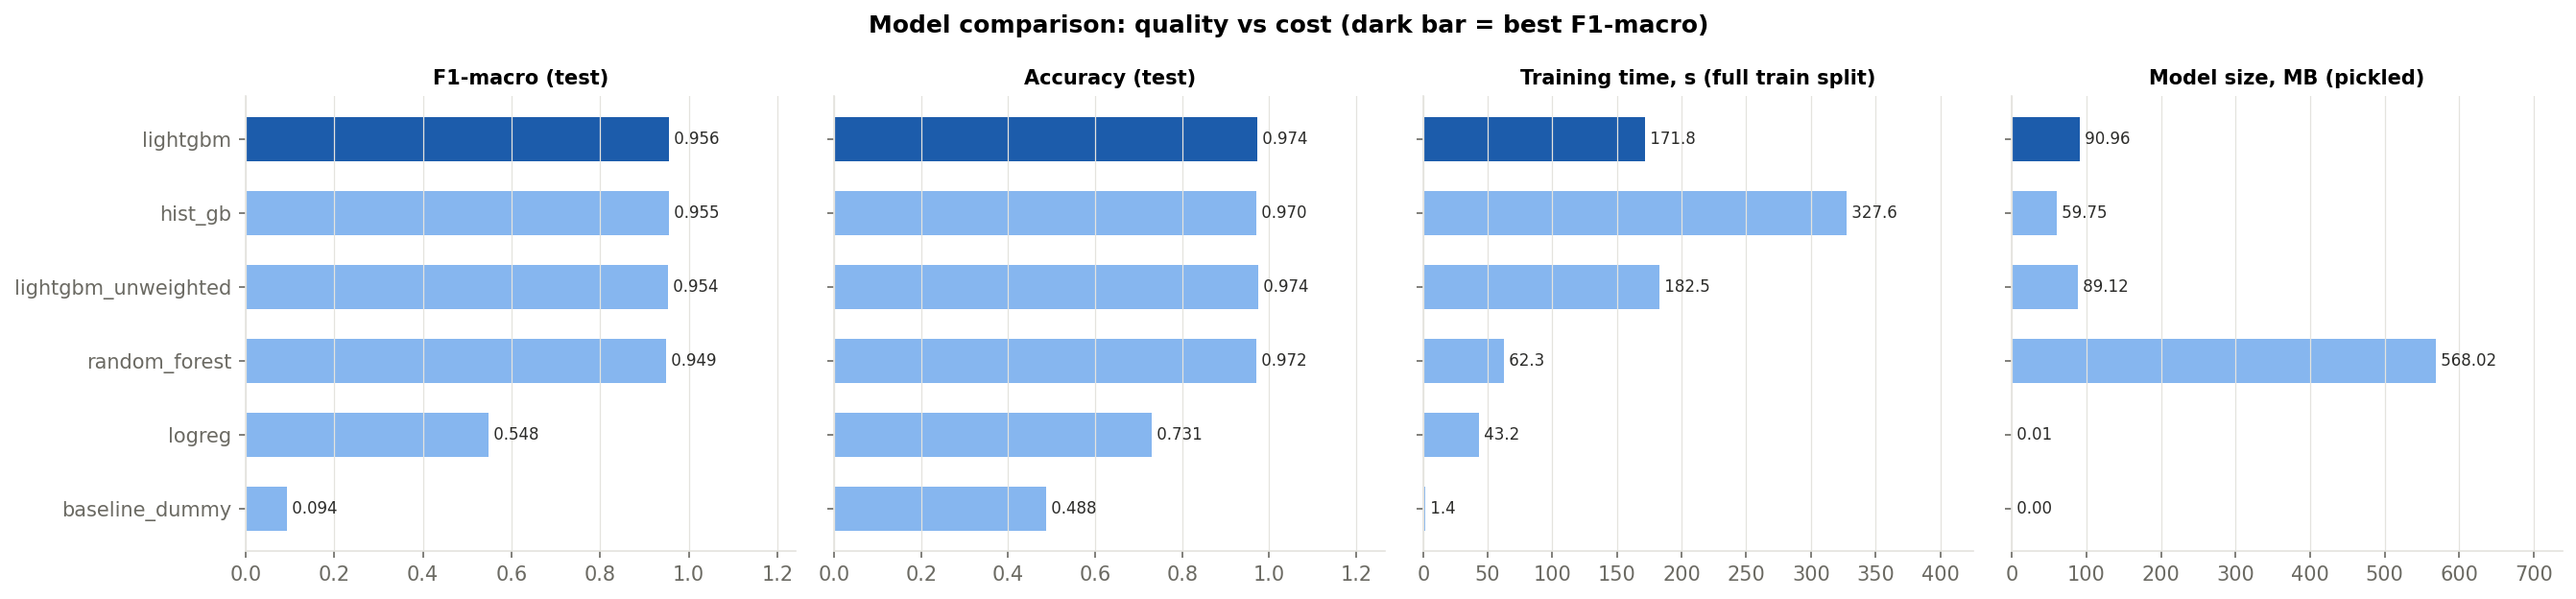

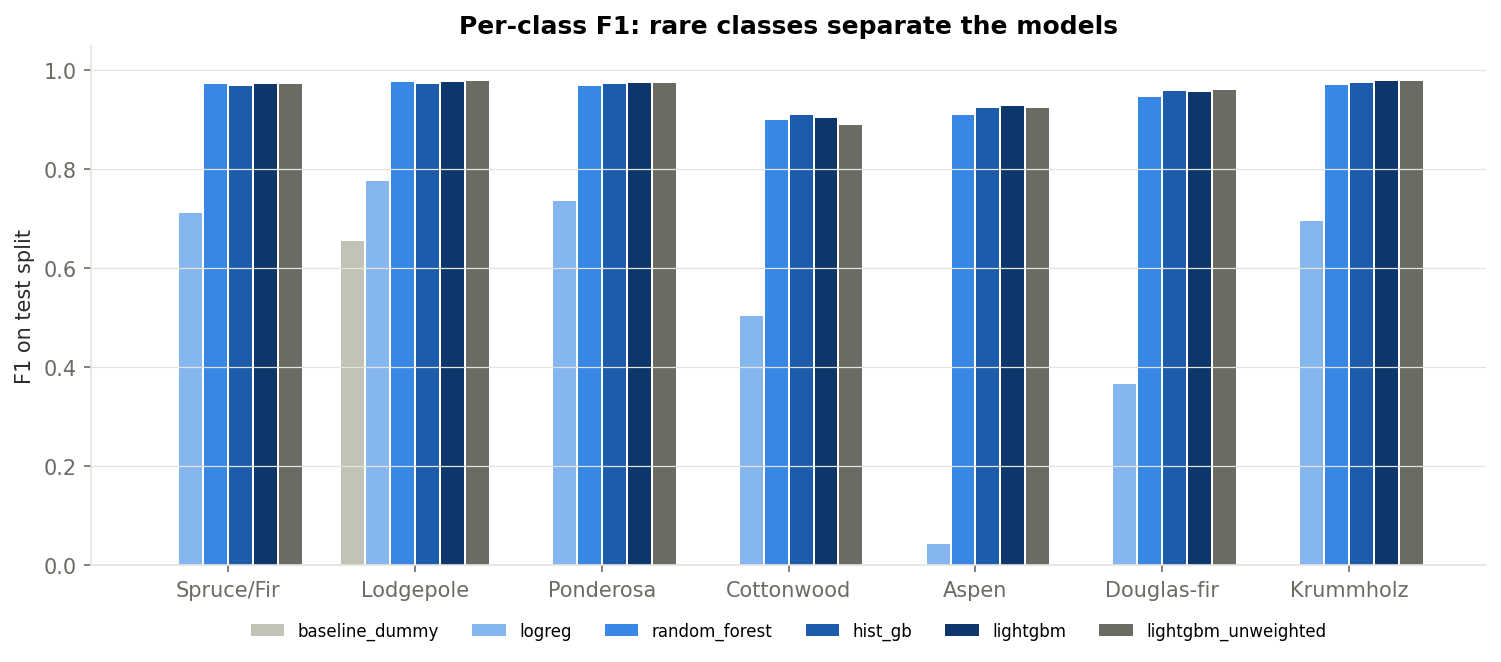

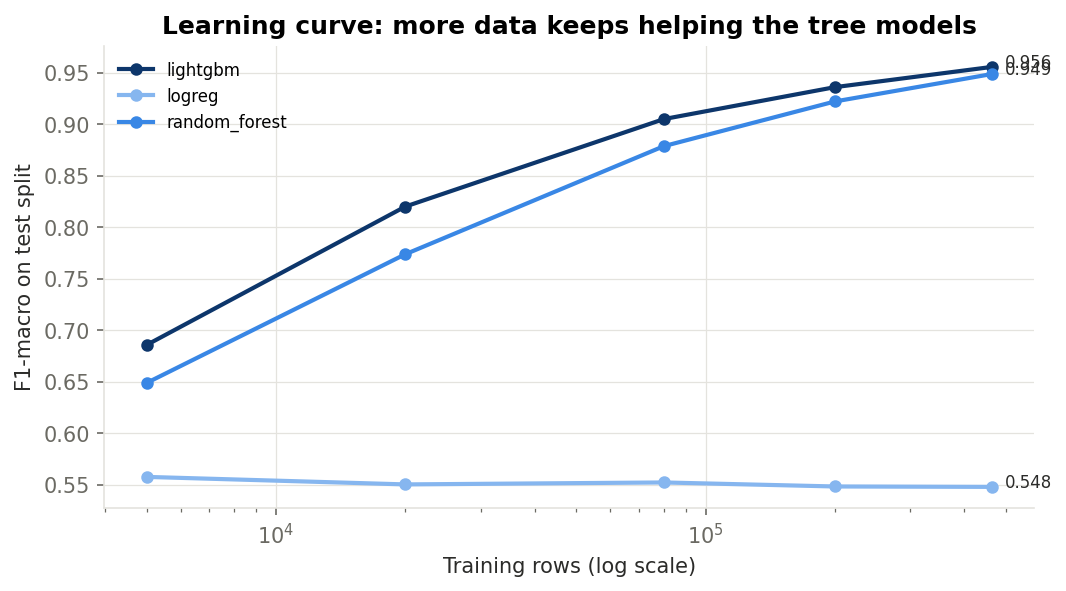

In [14]:
for name in ["11_model_comparison.png", "12_per_class_f1.png", "15_learning_curve.png"]:
    if (FIG / name).exists():
        display(Image(filename=str(FIG / name), width=1000))

In [15]:
# Optional: retrain the best model with its tuned parameters (about 3 min on 4 CPU threads).
# The repository already contains models/best_model.joblib, so this is off by default.
RETRAIN = False
X_train, X_test, y_train, y_test = features.split_data(df)
if RETRAIN or not config.BEST_MODEL_PATH.exists():
    meta = json.loads(config.BEST_MODEL_META.read_text())
    name = "lightgbm" if meta["model"].startswith("lightgbm") else meta["model"]
    model, cost = models.fit_final(name, meta["params"], X_train, y_train)
    models.save_model(model, meta)
    print("Retrained:", cost)
model = models.load_model()
model

,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('features', ...), ('columns', ...)]"
,transform_input,None
,memory,None
,verbose,False
,func,<function add...t 0x12eaf45c0>
,inverse_func,None
,validate,False


## 6. Evaluation of the best model on the hold-out test split

In [16]:
metrics, predictions = evaluate.score(model, X_test, y_test)
print(json.dumps(metrics, indent=1))
evaluate.report_table(y_test, predictions)

{
 "accuracy": 0.9736,
 "f1_macro": 0.9558,
 "f1_weighted": 0.9737,
 "balanced_accuracy": 0.959,
 "predict_seconds": 26.759,
 "predict_ms_per_1000": 230.281,
 "f1_Spruce/Fir": 0.9728,
 "f1_Lodgepole": 0.9772,
 "f1_Ponderosa": 0.9741,
 "f1_Cottonwood": 0.9036,
 "f1_Aspen": 0.9278,
 "f1_Douglas-fir": 0.9574,
 "f1_Krummholz": 0.9779
}


,precision,recall,f1-score,support
Spruce/Fir,0.9712,0.9743,0.9728,42368.0000
Lodgepole Pine,0.9799,0.9744,0.9772,56661.0000
Ponderosa Pine,0.9706,0.9776,0.9741,7151.0000
Cottonwood/Willow,0.9111,0.8962,0.9036,549.0000
Aspen,0.9086,0.9479,0.9278,1899.0000
Douglas-fir,0.9542,0.9606,0.9574,3473.0000
Krummholz,0.9737,0.9822,0.9779,4102.0000
accuracy,0.9736,0.9736,0.9736,0.9736
macro avg,0.9528,0.9590,0.9558,116203.0000
weighted avg,0.9737,0.9736,0.9737,116203.0000


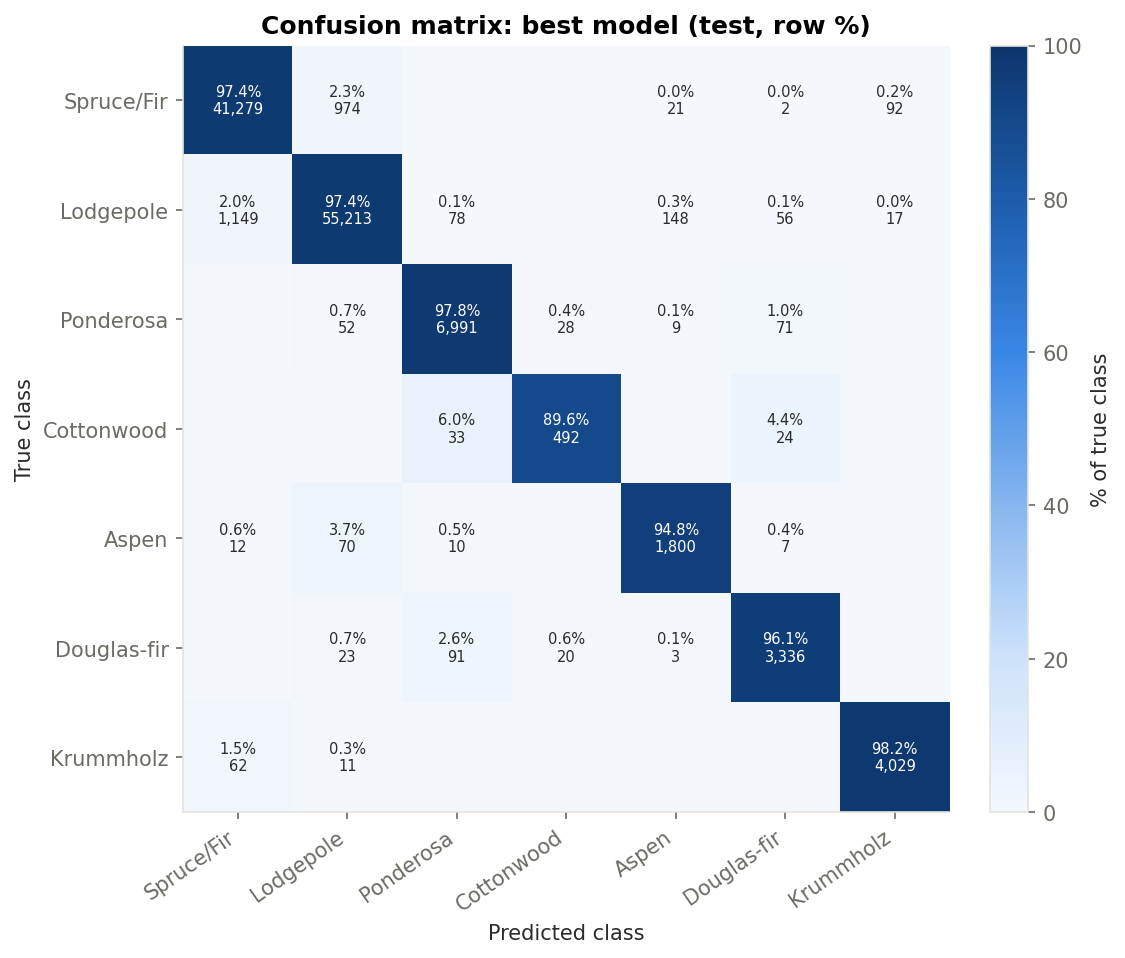

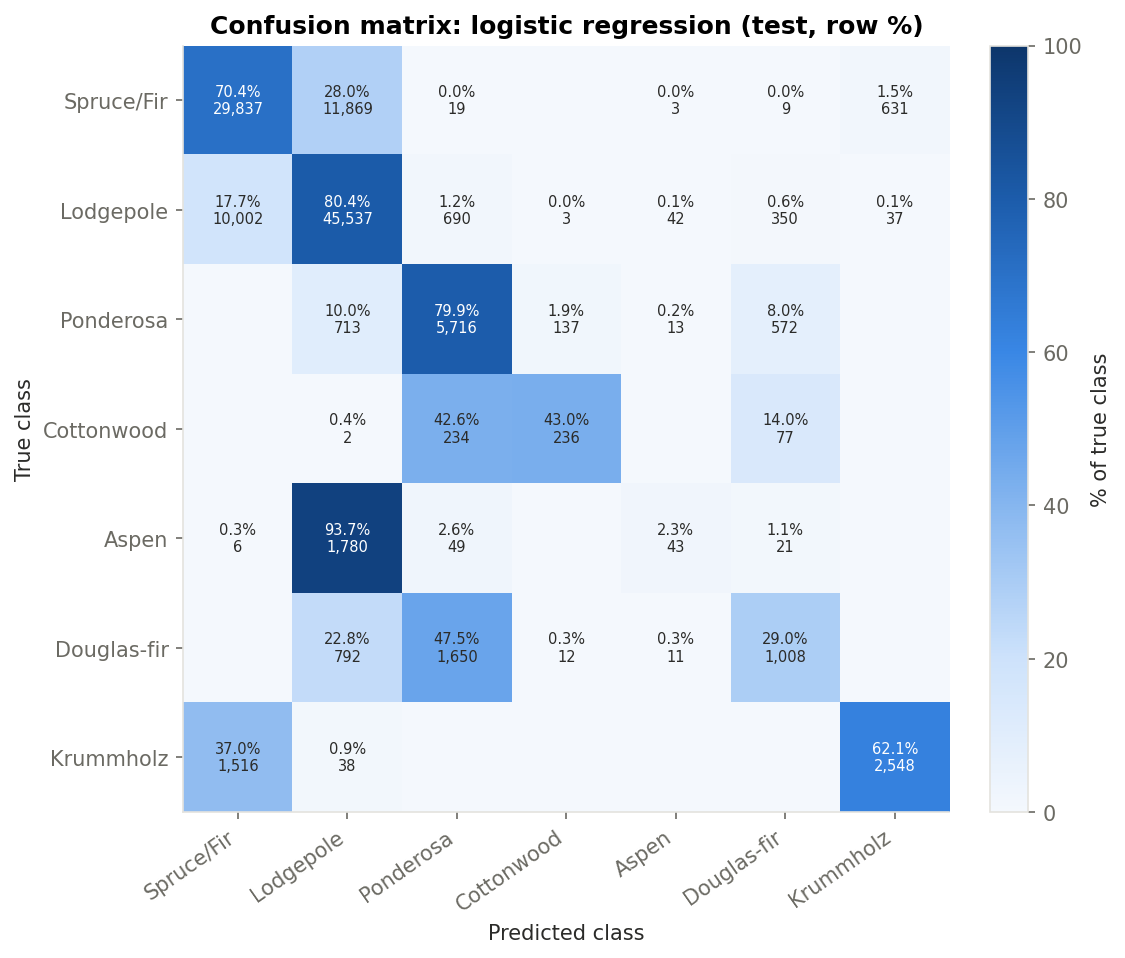

In [17]:
evaluate.plot_confusion(y_test, predictions, "Confusion matrix: best model (test, row %)", "10_confusion_best.png")
display(Image(filename=str(FIG / "10_confusion_best.png"), width=650))
display(Image(filename=str(FIG / "10b_confusion_logreg.png"), width=650))

,feature,importance_mean,importance_std
0,Elevation,0.6840,0.0042
1,Horizontal_Distance_To_Roadways,0.3495,0.0063
2,Horizontal_Distance_To_Fire_Points,0.3222,0.0048
3,Wilderness,0.2391,0.0068
4,Soil,0.1623,0.0037
5,Horizontal_Distance_To_Hydrology,0.1370,0.0060
6,Vertical_Distance_To_Hydrology,0.0909,0.0047
7,Aspect,0.0354,0.0036
8,Hillshade_9am,0.0191,0.0016
9,Hillshade_3pm,0.0081,0.0005


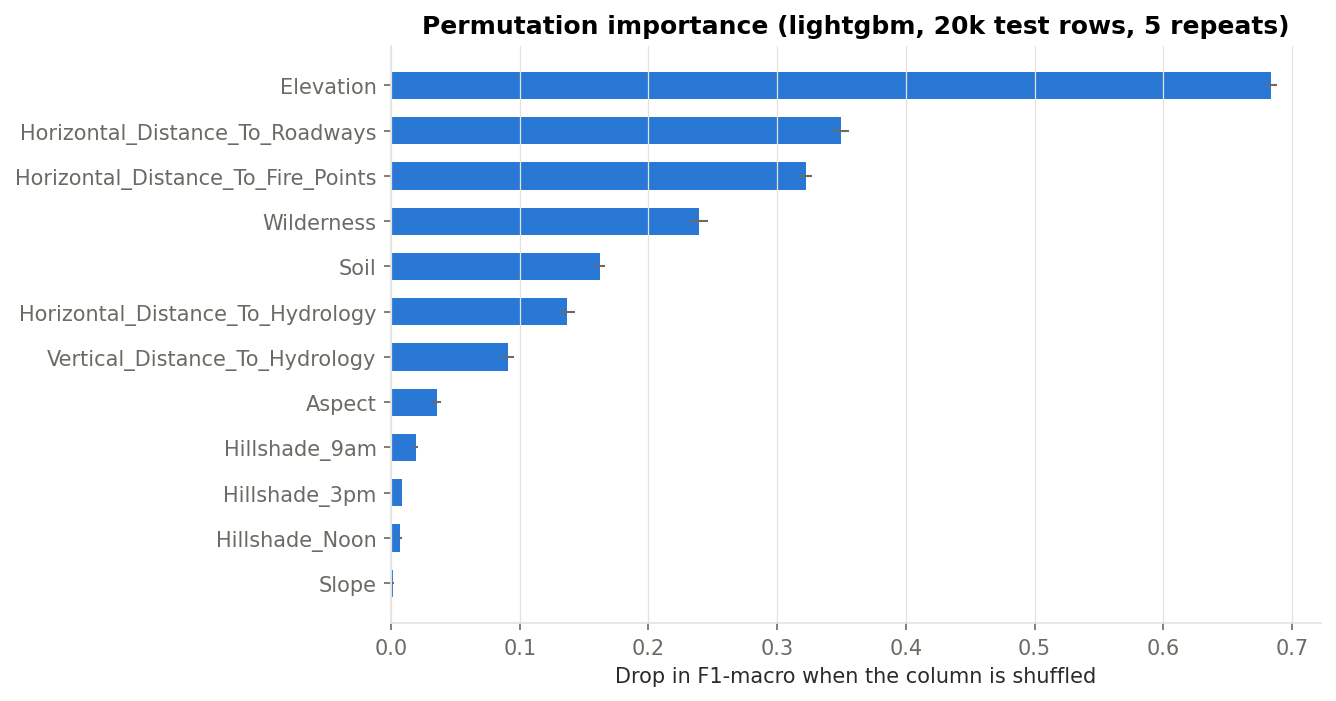

In [18]:
# Permutation importance (precomputed by menu step 6: 20k test rows x 5 repeats)
display(pd.read_csv(config.REPORTS_DIR / "permutation_importance.csv"))
display(Image(filename=str(FIG / "13_permutation_importance.png"), width=750))

In [19]:
analysis = evaluate.error_analysis(model, X_test, y_test, predictions)
print(analysis["summary"])
display(analysis["by_wilderness"])
display(analysis["confidence"])
display(analysis["confident_mistakes"].head(10))

{'test_rows': 116203, 'errors': 3063, 'share_low_confidence': 0.0167, 'error_rate_low_confidence': 0.4521, 'error_rate_high_confidence': 0.0191}


,n,error_rate
Rawah,52275,0.0253
Neota,6014,0.0165
Comanche Peak,50577,0.0282
Cache la Poudre,7337,0.0290


,mean,25%,50%,75%
correct,0.9662,0.9735,0.9949,0.9993
wrong,0.7235,0.5860,0.7003,0.8530


,Elevation,Wilderness,Soil,true_name,pred_name,confidence
5327,2244,4,17,Ponderosa Pine,Cottonwood/Willow,1.0
264045,2150,4,14,Ponderosa Pine,Cottonwood/Willow,1.0
269735,2285,4,16,Douglas-fir,Cottonwood/Willow,1.0
295884,2332,4,2,Ponderosa Pine,Cottonwood/Willow,1.0
3099,2071,4,4,Cottonwood/Willow,Ponderosa Pine,1.0
288234,2228,4,14,Douglas-fir,Cottonwood/Willow,1.0
2553,2050,4,17,Cottonwood/Willow,Ponderosa Pine,1.0
260557,2125,4,14,Ponderosa Pine,Cottonwood/Willow,1.0
12506,2036,4,6,Cottonwood/Willow,Ponderosa Pine,1.0
288134,2286,4,3,Ponderosa Pine,Cottonwood/Willow,1.0


In [20]:
# Store predictions in SQLite and analyse the errors with SQL (Q10-Q12)
from contextlib import closing
with closing(database.connect()) as con:
    database.save_split(con, X_train.index, X_test.index)
    model_id = database.register_model(con, "lightgbm", "boosting", {})
    database.save_experiment(con, model_id, {**metrics, "train_seconds": None, "model_size_mb": None})
    database.save_predictions(con, model_id, X_test.index, predictions)
for key in ["Q11_top_confusions", "Q12_error_rate_by_area_and_band"]:
    print("---", queries.QUERIES[key]["title"])
    display(queries.run_query(key)[0].head(12))

--- Top-2 confusions per true class for the best model


,true_class,predicted_as,n,errors_of_class
0,Lodgepole Pine,Spruce/Fir,1149,1448
1,Lodgepole Pine,Aspen,148,1448
2,Spruce/Fir,Lodgepole Pine,974,1089
3,Spruce/Fir,Krummholz,92,1089
4,Ponderosa Pine,Douglas-fir,71,160
5,Ponderosa Pine,Lodgepole Pine,52,160
6,Douglas-fir,Ponderosa Pine,91,137
7,Douglas-fir,Lodgepole Pine,23,137
8,Aspen,Lodgepole Pine,70,99
9,Aspen,Spruce/Fir,12,99


--- Error rate of the best model by wilderness area and elevation band


,wilderness,band_start,n_test,error_pct,change_vs_lower_band
0,Cache la Poudre,1750,275,0.73,NaN
1,Cache la Poudre,2000,2341,3.50,2.77
2,Cache la Poudre,2250,4150,2.70,-0.80
3,Cache la Poudre,2500,571,2.98,0.28
4,Comanche Peak,2250,1303,4.07,NaN
5,Comanche Peak,2500,7976,3.89,-0.18
6,Comanche Peak,2750,16215,3.02,-0.87
7,Comanche Peak,3000,18503,2.50,-0.52
8,Comanche Peak,3250,6461,1.75,-0.75
9,Neota,3000,3125,1.73,NaN


## 7. Prediction for user input

In [21]:
record = dict(predict.EXAMPLE_RECORD)
print(record)
predict.predict_record(record, model=model)

{'Elevation': 2800, 'Aspect': 150, 'Slope': 12, 'Horizontal_Distance_To_Hydrology': 250, 'Vertical_Distance_To_Hydrology': 40, 'Horizontal_Distance_To_Roadways': 2000, 'Hillshade_9am': 220, 'Hillshade_Noon': 225, 'Hillshade_3pm': 140, 'Horizontal_Distance_To_Fire_Points': 1800, 'Wilderness': 1, 'Soil': 29}


[{'cover_type_id': 2, 'cover_type': 'Lodgepole Pine', 'probability': 0.9935},
 {'cover_type_id': 1, 'cover_type': 'Spruce/Fir', 'probability': 0.0064},
 {'cover_type_id': 5, 'cover_type': 'Aspen', 'probability': 0.0}]

In [22]:
# A high, rocky cell in Neota: expected Krummholz / Spruce-Fir
record.update({"Elevation": 3450, "Slope": 18, config.WILDERNESS: 2, config.SOIL: 38,
               "Horizontal_Distance_To_Roadways": 1500})
predict.predict_record(record, model=model)

[{'cover_type_id': 7, 'cover_type': 'Krummholz', 'probability': 0.9998},
 {'cover_type_id': 1, 'cover_type': 'Spruce/Fir', 'probability': 0.0002},
 {'cover_type_id': 2, 'cover_type': 'Lodgepole Pine', 'probability': 0.0}]

In [23]:
# Invalid input is rejected with a clear message (try/except, requirement 6)
try:
    predict.predict_record({**record, "Slope": 140}, model=model)
except ValueError as error:
    print("Rejected:", error)

Rejected: Slope must be between 0 and 90, got 140


## Conclusions

* Gradient boosting (LightGBM) is the best model: F1-macro ≈ 0.956 and accuracy ≈ 0.974 on
  116,203 test cells, against 0.094 for the majority baseline and 0.548 for Logistic Regression.
* Random Forest is almost as accurate (0.949) and trains faster, but its model is 6× larger.
* The classes are not linearly separable: the linear model cannot express "elevation belt ×
  soil × area" interactions, so it loses 40 points of F1-macro, mostly on rare classes.
* Class weighting is a small but consistent gain for the rare classes (balanced accuracy
  +1.2 points) at no cost in accuracy.
* About 69% of the remaining errors are Spruce/Fir ↔ Lodgepole Pine confusions, and most errors
  lie at 2,750–3,250 m, where both species grow on the same terrain.
* Limitation: the random split ignores spatial autocorrelation between neighbouring cells, so
  the score is optimistic for a completely new region.